# Phase-Aware Learning Rate Restarts — Analysis

**Questions:** (1) Do phase-aware LR restarts improve *fixed-final* ID Binding relative to a matched global schedule? (2) Are results consistent across paired seeds and on OOD Binding? (3) Does each policy change Shape/Conjunction retention, error types, or gradient/LR exposure? (4) Is any apparent gain just larger cumulative LR? Read saved results only; **never retrain inside this notebook**.

Interpret the first three LR policies (Constant, Global Cosine, Reset Cosine) before extending to the two plateau variants. The fixed final checkpoint is step 9,000. ID-dev Binding is the primary comparison; OOD-dev and error diagnostics are secondary. Treat repeated OOD-dev analysis as exploratory; historical test data are not sealed for every earlier study.

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path().cwd().parent.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

SEEDS = [42,43,44,45,46]
SCHEDULES = ("prereq_mixed_pair_focus", "staged_rehearsal", "scaffolded_spiral", "mixed")
ANALYZE_POLICIES = ("constant", "global_cosine", "reset_cosine", "global_plateau", "reset_plateau")
# To add completed plateau runs: ANALYZE_POLICIES = (..., "global_plateau", "reset_plateau")
RESULT_DIR = PROJECT_ROOT / "outputs/medium_world/experiments/phase_aware_lr"
DATA_DIR = PROJECT_ROOT / "outputs/medium_world/dataset"
REPORT_FILE = RESULT_DIR / "schedule_comparison.json"

In [2]:
import json, hashlib, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.medium_visual_world.learning import TASKS
from src.medium_visual_world.prediction_tracking import (
    load_trace, compare_two, compare_three, summarize_changes
)

report = json.loads(REPORT_FILE.read_text(encoding="utf-8"))
hashes = {name: hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest()
          for name in ("train.jsonl", "id_dev.jsonl", "ood_dev.jsonl")}
assert report["config"]["dataset_hashes"] == hashes
runs = [r for r in report["runs"] if r["policy"] in ANALYZE_POLICIES]
expected = {(seed,schedule,policy) for seed in SEEDS for schedule in SCHEDULES
            for policy in ANALYZE_POLICIES}
actual = {(r["seed"],r["schedule"],r["policy"]) for r in runs}
assert actual == expected and len(runs) == len(expected), "Finish all requested runs before analysis"
lookup = {(r["seed"],r["schedule"],r["policy"]):r for r in runs}
print("Analyzing",len(runs),"completed runs | dataset hashes matched")

Analyzing 100 completed runs | dataset hashes matched


## Final outcome: paired policy comparisons

Report per-seed points and the paired mean ± two-sided 95% Student-*t* interval (`n=5`). We compare LR policies **within the same curriculum and seed**. Differences expressed in percentage points. The five seeds provide descriptive uncertainty, not a large-sample guarantee. Do not select a best training checkpoint.

In [3]:
final_rows = []
for r in runs:
    f = r["final"]
    row = {"seed":r["seed"],"schedule":r["schedule"],"policy":r["policy"],
           "id_pair":100*f["id_dev"]["by_template"]["pair"],
           "ood_pair":100*f["ood_dev"]["by_template"]["pair"],
           "id_pair_aulc":100*r["id_pair_aulc"],
           "id_pair_ce":f["id_dev"]["loss_by_template"]["pair"],
           "ood_pair_ce":f["ood_dev"]["loss_by_template"]["pair"]}
    for task in TASKS:
        row[f"id_{task}"] = 100*f["id_dev"]["by_template"][task]
    for split in ("id_dev","ood_dev"):
        scores=f[split]["binary_by_template"]["pair"]
        prefix="id" if split=="id_dev" else "ood"
        row[f"{prefix}_tpr"]=100*scores["positive_recall"]
        row[f"{prefix}_tnr"]=100*scores["negative_specificity"]
        row[f"{prefix}_positive_rate"]=100*scores["predicted_positive_rate"]
    final_rows.append(row)
final=pd.DataFrame(final_rows).sort_values(["schedule","seed","policy"])
final.to_csv(RESULT_DIR/"final_by_seed.csv",index=False)
display(final.groupby(["schedule","policy"])[["id_pair","ood_pair","id_pair_aulc",
    "id_shape","id_conjunction","ood_tpr","ood_tnr"]].mean().round(2))

CONTRASTS = [("global_cosine","constant"),("reset_cosine","global_cosine"),
             ("reset_cosine","constant"),("reset_plateau","global_plateau")]
T95 = 2.7764451051977987
paired_rows=[]
for schedule in SCHEDULES:
    subset=final[final.schedule==schedule]
    for left,right in CONTRASTS:
        if left not in ANALYZE_POLICIES or right not in ANALYZE_POLICIES:
            continue
        a=subset[subset.policy==left].set_index("seed")
        b=subset[subset.policy==right].set_index("seed")
        for metric in ("id_pair","ood_pair","id_pair_aulc","id_shape",
                       "id_conjunction","ood_tpr","ood_tnr","ood_pair_ce"):
            d=a[metric]-b[metric]
            n=len(d); mean=float(d.mean()); margin=T95*float(d.std(ddof=1))/math.sqrt(n)
            paired_rows.append({"schedule":schedule,"contrast":left+" - "+right,
                "metric":metric,"unit":"nats" if metric.endswith("_ce") else "pp",
                "n_seeds":n,"difference":mean,
                "ci95_low":mean-margin,"ci95_high":mean+margin,
                "positive_seeds":int((d>0).sum()),
                "seed_differences":json.dumps({str(k):float(v) for k,v in d.items()})})
paired=pd.DataFrame(paired_rows)
paired.to_csv(RESULT_DIR/"paired_differences.csv",index=False)
display(paired[paired.metric.isin(["id_pair","ood_pair","id_pair_aulc"])].round(3))

id_pair  ood_pair  id_pair_aulc  \
schedule                policy                                            
mixed                   constant          62.03     56.65         56.77   
                        global_cosine     56.95     55.10         55.30   
                        global_plateau    58.98     54.85         56.14   
                        reset_cosine      56.95     55.15         55.28   
                        reset_plateau     58.36     55.15         55.87   
prereq_mixed_pair_focus constant          62.89     57.20         54.97   
                        global_cosine     54.69     55.05         52.39   
                        global_plateau    51.41     52.35         50.78   
                        reset_cosine      57.58     56.60         53.72   
                        reset_plateau     58.20     57.35         53.95   
scaffolded_spiral       constant          61.17     56.15         55.00   
                        global_cosine     56.80     53.55         53.29   
                        global_plateau    53.12     52.35         52.52   
                        reset_cosine      58.28     56.80         54.21   
                        reset_plateau     60.55     56.80         54.68   
staged_rehearsal        constant          63.28     56.20         55.20   
                        global_cosine     57.03     53.20         53.15   
                        global_plateau    53.12     50.70         52.01   
                        reset_cosine      59.06     56.35         54.27   
                        reset_plateau     59.92     56.40         54.77   

                                        id_shape  id_conjunction  ood_tpr  \
schedule                policy                                              
mixed                   constant           67.81           79.53     77.0   
                        global_cosine      63.75           79.61     72.0   
                        global_plateau     65.31           79.69     70.5   
                        reset_cosine       63.52           79.61     72.1   
                        reset_plateau      65.31           79.53     72.2   
prereq_mixed_pair_focus constant           66.88           80.78     66.7   
                        global_cosine      64.14           78.75     69.7   
                        global_plateau     62.42           77.27     74.5   
                        reset_cosine       63.83           79.06     72.8   
                        reset_plateau      63.44           79.84     74.6   
scaffolded_spiral       constant           67.58           80.55     61.2   
                        global_cosine      66.09           79.38     61.4   
                        global_plateau     61.64           77.19     77.1   
                        reset_cosine       65.39           79.06     73.9   
                        reset_plateau      65.39           79.77     74.3   
staged_rehearsal        constant           67.03           80.55     60.3   
                        global_cosine      64.22           79.84     62.7   
                        global_plateau     60.62           77.27     78.5   
                        reset_cosine       63.91           78.98     70.6   
                        reset_plateau      65.16           79.53     67.0   

                                        ood_tnr  
schedule                policy                   
mixed                   constant           36.3  
                        global_cosine      38.2  
                        global_plateau     39.2  
                        reset_cosine       38.2  
                        reset_plateau      38.1  
prereq_mixed_pair_focus constant           47.7  
                        global_cosine      40.4  
                        global_plateau     30.2  
                        reset_cosine       40.4  
                        reset_plateau      40.1  
scaffolded_spiral       constant           51.1  
                        global_cosine      4

,schedule,contrast,metric,unit,n_seeds,difference,ci95_low,ci95_high,positive_seeds,seed_differences
0,prereq_mixed_pair_focus,global_cosine - constant,id_pair,pp,5,-8.203,-13.891,-2.516,0,"{""42"": -10.15625, ""43"": -6.640625, ""44"": -13.2..."
1,prereq_mixed_pair_focus,global_cosine - constant,ood_pair,pp,5,-2.150,-6.099,1.799,1,"{""42"": -7.000000000000007, ""43"": 0.0, ""44"": -3..."
2,prereq_mixed_pair_focus,global_cosine - constant,id_pair_aulc,pp,5,-2.579,-3.756,-1.401,0,"{""42"": -3.281250000000007, ""43"": -2.01171875, ..."
8,prereq_mixed_pair_focus,reset_cosine - global_cosine,id_pair,pp,5,2.891,0.760,5.021,5,"{""42"": 5.859375, ""43"": 1.953125, ""44"": 2.73437..."
9,prereq_mixed_pair_focus,reset_cosine - global_cosine,ood_pair,pp,5,1.550,-1.596,4.696,4,"{""42"": 4.75, ""43"": -2.250000000000007, ""44"": 2..."
10,prereq_mixed_pair_focus,reset_cosine - global_cosine,id_pair_aulc,pp,5,1.324,0.543,2.105,5,"{""42"": 2.0464409722222356, ""43"": 1.09157986111..."
16,prereq_mixed_pair_focus,reset_cosine - constant,id_pair,pp,5,-5.312,-10.348,-0.277,1,"{""42"": -4.296875, ""43"": -4.6875, ""44"": -10.546..."
17,prereq_mixed_pair_focus,reset_cosine - constant,ood_pair,pp,5,-0.600,-3.137,1.937,1,"{""42"": -2.250000000000007, ""43"": -2.2500000000..."
18,prereq_mixed_pair_focus,reset_cosine - constant,id_pair_aulc,pp,5,-1.254,-1.764,-0.744,0,"{""42"": -1.2348090277777715, ""43"": -0.920138888..."
24,prereq_mixed_pair_focus,reset_plateau - global_plateau,id_pair,pp,5,6.797,4.171,9.422,5,"{""42"": 7.03125, ""43"": 7.421875, ""44"": 8.203125..."


## Learning dynamics and effective LR exposure

Plot *global-step* Binding learning curves (shared 100-update grid), then compare accuracy versus cumulative Binding presentations. The latter aligns question counts but **not** total optimizer steps or LR-weighted exposure. For Reset Cosine, inspect its larger number of LR cycles and the measured LR applied to each task before attributing a gain to "restarting" itself.

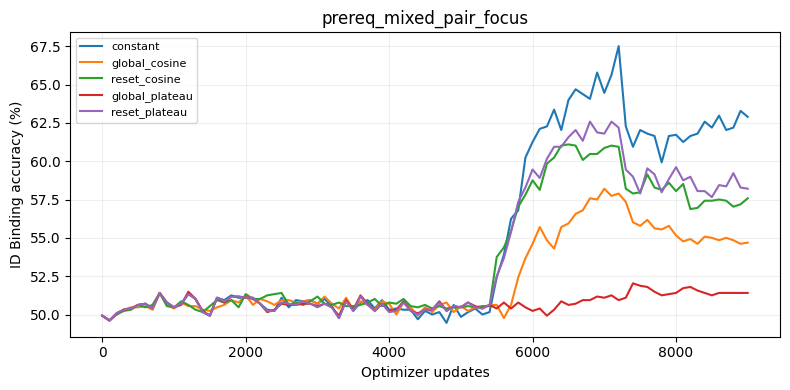

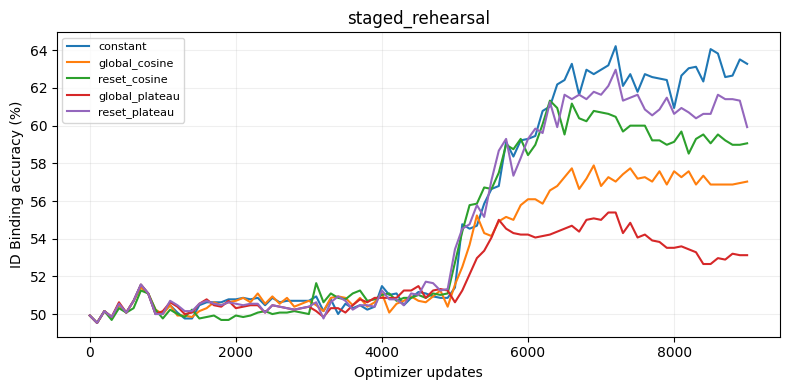

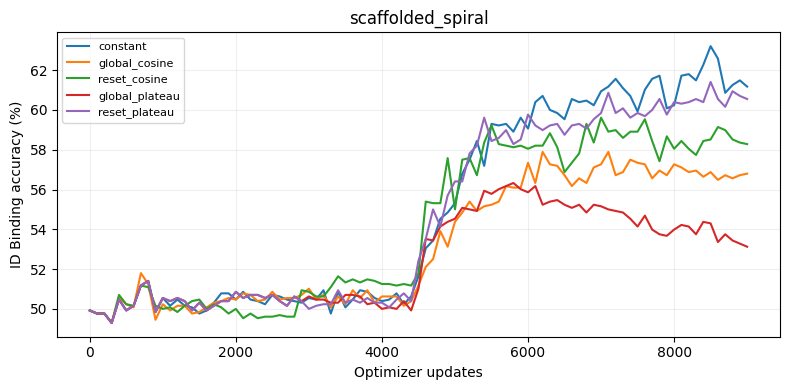

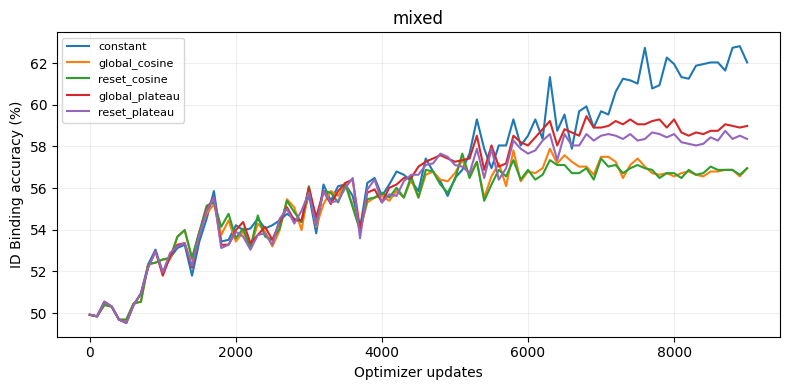

task                                     color  conjunction    pair   shape
schedule                policy                                             
mixed                   constant        11.250       11.250  11.250  11.250
                        global_cosine    5.686        5.676   5.681   5.682
                        global_plateau   6.398        6.386   6.393   6.392
                        reset_cosine     5.686        5.676   5.681   5.682
                        reset_plateau    6.257        6.245   6.251   6.251
prereq_mixed_pair_focus constant        11.250       11.250  11.250  11.250
                        global_cosine    6.890        6.883   2.063   6.888
                        global_plateau   4.936        4.925   0.203   4.936
                        reset_cosine     5.123        5.113   5.119   5.121
                        reset_plateau    5.944        5.933   6.108   5.944
scaffolded_spiral       constant        11.250       11.250  11.250  11.250
                        global_cosine    7.374        5.029   2.951   7.371
                        global_plateau   4.485        1.105   0.934   4.476
                        reset_cosine     5.131        5.118   5.110   5.115
                        reset_plateau    6.549        7.936   8.553   6.535
staged_rehearsal        constant        11.250       11.250  11.250  11.250
                        global_cosine    7.589        5.179   2.370   7.587
                        global_plateau   4.838        0.947   0.297   4.835
                        reset_cosine     5.125        5.115   5.117   5.118
                        reset_plateau    6.546        6.982   7.575   6.540

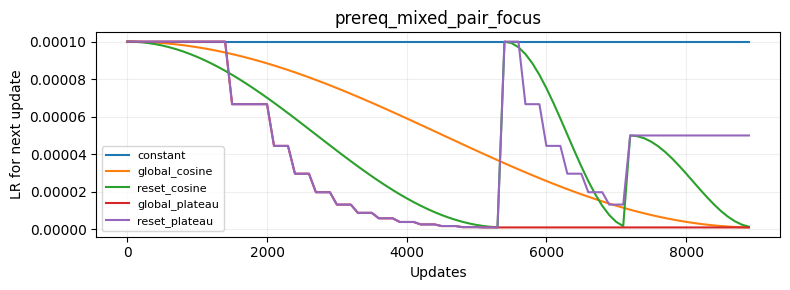

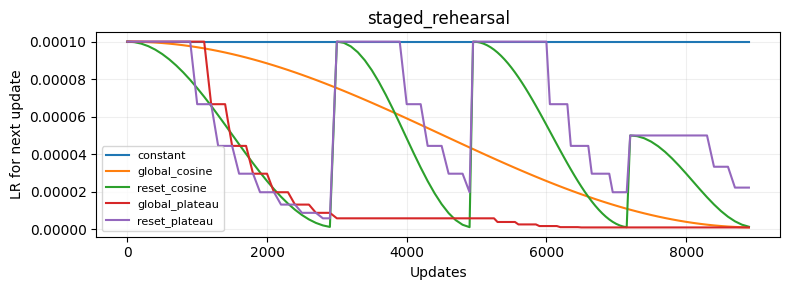

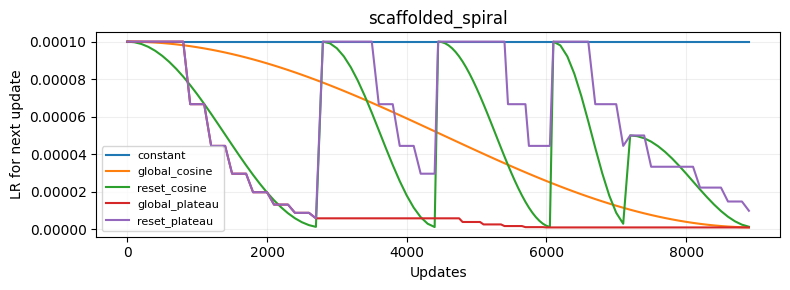

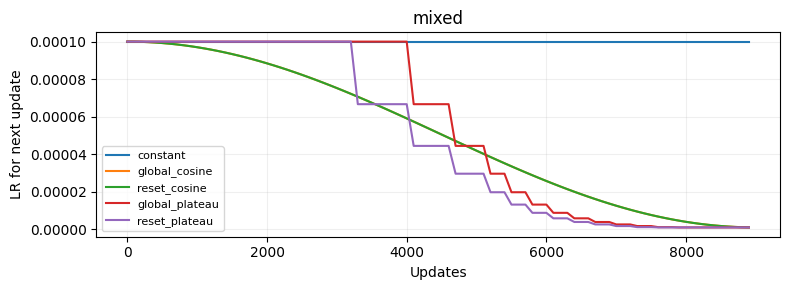

In [4]:
history_rows=[]
for r in runs:
    for h in r["history"]:
        row={"seed":r["seed"],"schedule":r["schedule"],"policy":r["policy"],
             "step":h["step"],"phase":h["phase"],"lr":h["lr_next_update"],
             "id_pair":100*h["id_dev"]["by_template"]["pair"],
             "ood_pair":100*h["ood_dev"]["by_template"]["pair"],
             "id_shape":100*h["id_dev"]["by_template"]["shape"],
             "id_conjunction":100*h["id_dev"]["by_template"]["conjunction"],
             "pair_exposure":h["cumulative_task_presentations"].get("pair",0)}
        history_rows.append(row)
curves=pd.DataFrame(history_rows)
curves.to_csv(RESULT_DIR/"learning_curves.csv",index=False)
for schedule in SCHEDULES:
    frame=curves[(curves.schedule==schedule) & (curves.step%100==0)]
    fig,ax=plt.subplots(figsize=(8,4))
    for policy in ANALYZE_POLICIES:
        part=frame[frame.policy==policy].groupby("step",as_index=False)["id_pair"].mean()
        ax.plot(part.step,part.id_pair,label=policy)
    ax.set(xlabel="Optimizer updates",ylabel="ID Binding accuracy (%)",title=schedule)
    ax.grid(alpha=.2);ax.legend(fontsize=8)
    fig.tight_layout();fig.savefig(RESULT_DIR/f"curve_{schedule}.png",dpi=160);plt.show()

lr_rows=[]
for r in runs:
    for task in TASKS:
        lr_rows.append({"seed":r["seed"],"schedule":r["schedule"],
                        "policy":r["policy"],"task":task,
                        "lr_times_presentations":r["cumulative_lr_by_task"].get(task,0),
                        "restarts":len(r["reset_events"])})
lr_exposure=pd.DataFrame(lr_rows)
lr_exposure.to_csv(RESULT_DIR/"lr_exposure.csv",index=False)
display(lr_exposure.groupby(["schedule","policy","task"])
        ["lr_times_presentations"].mean().unstack("task").round(3))

for schedule in SCHEDULES:
    fig,ax=plt.subplots(figsize=(8,3))
    frame=curves[(curves.schedule==schedule)&(curves.seed==SEEDS[0])]
    for policy in ANALYZE_POLICIES:
        part=frame[frame.policy==policy]
        ax.plot(part.step,part.lr,label=policy)
    ax.set(xlabel="Updates",ylabel="LR for next update",title=schedule)
    ax.grid(alpha=.2);ax.legend(fontsize=8)
    fig.tight_layout();fig.savefig(RESULT_DIR/f"lr_{schedule}.png",dpi=160);plt.show()

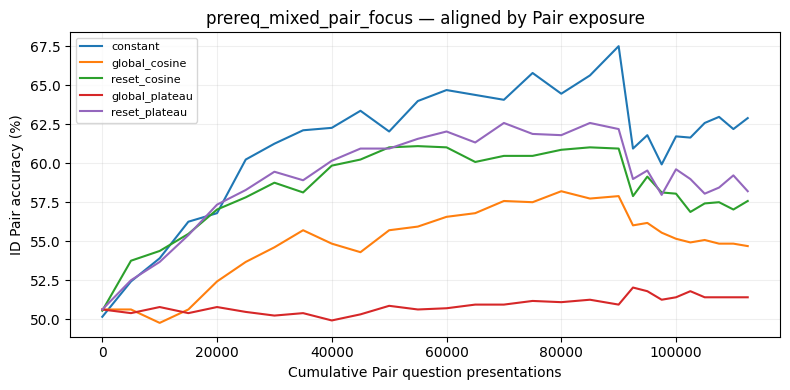

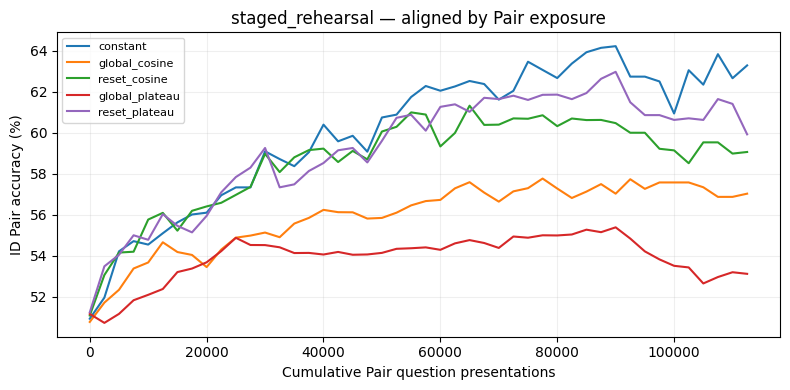

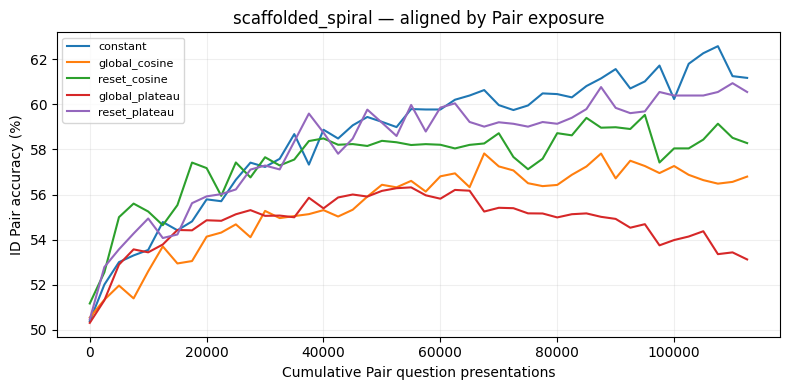

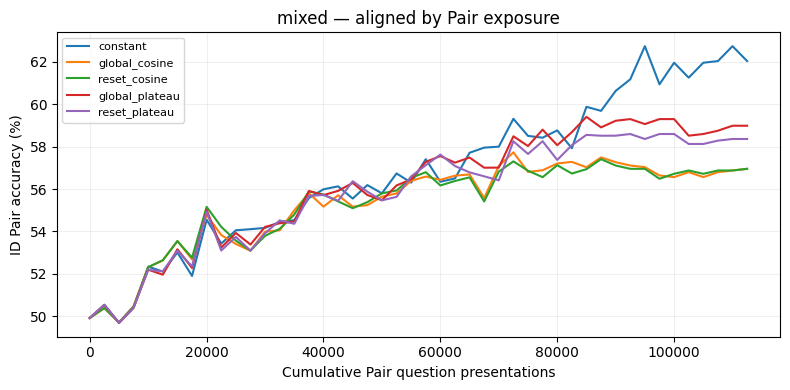

In [5]:
# Compare Binding accuracy at matched cumulative question exposure within each schedule.
exposure_rows=[]
for schedule in SCHEDULES:
    fig,ax=plt.subplots(figsize=(8,4))
    for policy in ANALYZE_POLICIES:
        aligned=[]
        for seed in SEEDS:
            part=curves[(curves.schedule==schedule)&(curves.policy==policy)&
                        (curves.seed==seed)].sort_values("step")
            part=part.drop_duplicates("pair_exposure",keep="last")
            grid=np.linspace(0,112500,46)
            values=np.interp(grid,part.pair_exposure,part.id_pair)
            aligned.append(values)
            exposure_rows.extend({"schedule":schedule,"policy":policy,"seed":seed,
                "pair_exposure":float(x),"id_pair":float(y)} for x,y in zip(grid,values))
        ax.plot(grid,np.mean(aligned,axis=0),label=policy)
    ax.set(xlabel="Cumulative Pair question presentations",ylabel="ID Pair accuracy (%)",
           title=schedule+" — aligned by Pair exposure")
    ax.grid(alpha=.2);ax.legend(fontsize=8)
    fig.tight_layout();fig.savefig(RESULT_DIR/f"exposure_{schedule}.png",dpi=160);plt.show()
pd.DataFrame(exposure_rows).to_csv(RESULT_DIR/"pair_exposure_curves.csv",index=False)

## At the real curriculum transitions: interference and recovery

Use the *same exact question IDs* in the saved prediction traces. For each true change of task mixture, compare predictions at the boundary and 100 updates later, then check recovery by step 9,000. These are **accuracy-state changes**, not proof that a representation has been erased. Transition effects are not directly comparable across curricula unless their task exposures and model states are matched.

In [6]:
traces={(r["seed"],r["schedule"],r["policy"]):load_trace(
    RESULT_DIR/r["prediction_trace"]) for r in runs}
change_rows=[]
for r in runs:
    trace=traces[(r["seed"],r["schedule"],r["policy"])]
    for segment in r["effective_phases"][1:]:
        boundary=segment["start_step"]
        for split,block in trace["splits"].items():
            changed=compare_three(block,boundary,boundary+100,9000)
            stats=summarize_changes(changed)
            for _,item in stats.iterrows():
                change_rows.append({"seed":r["seed"],"schedule":r["schedule"],
                    "policy":r["policy"],"split":split,"boundary":boundary,**item.to_dict()})
changes=pd.DataFrame(change_rows)
changes.to_csv(RESULT_DIR/"prediction_change_summary.csv",index=False)
display(changes[(changes.split=="id_dev") & (changes.task.isin(["shape","conjunction","pair"]))]
    .groupby(["schedule","policy","boundary","task"])
    [["forgetting_rate","newly_learned_rate","correctness_churn"]].mean().round(3).head(36))

forgetting_rate  \
schedule                policy         boundary task                           
prereq_mixed_pair_focus constant       5400     conjunction            0.190   
                                                pair                   0.386   
                                                shape                  0.269   
                                       7200     conjunction            0.115   
                                                pair                   0.184   
                                                shape                  0.185   
                        global_cosine  5400     conjunction            0.194   
                                                pair                   0.380   
                                                shape                  0.193   
                                       7200     conjunction            0.068   
                                                pair                   0.140   
                                                shape                  0.108   
                        global_plateau 5400     conjunction            0.011   
                                                pair                   0.060   
                                                shape                  0.036   
                                       7200     conjunction            0.009   
                                                pair                   0.032   
                                                shape                  0.016   
                        reset_cosine   5400     conjunction            0.222   
                                                pair                   0.413   
                                                shape                  0.235   
                                       7200     conjunction            0.100   
                                                pair                   0.151   
                                                shape                  0.217   
                        reset_plateau  5400     conjunction            0.224   
                                                pair                   0.380   
                                                shape                  0.291   
                                       7200     conjunction            0.098   
                                                pair                   0.167   
                                                shape                  0.219   
scaffolded_spiral       constant       2800     conjunction            0.051   
                                                pair                   0.096   
                                                shape                  0.125   
                                       4450     conjunction            0.083   
                                                pair                   0.363   
                                                shape                  0.117   

                                                             newly_learned_rate  \
schedule                policy         boundary task                              
prereq_mixed_pair_focus constant       5400     conjunction               0.389   
                                                pair                      0.435   
                                                shape                     0.284   
                                       7200     conjunction               0.456   
                                                pair                      0.226   
                                                shape                     0.420   
                        global_cosine  5400     conjunction               0.390   
                                                pair                      0.389   
                                                shape                     0.205   
                                       7200     conjunction               0.285   
                        

## Error types: conjunction shortcuts, class bias, held-out pairs

Compare OOD positive recall against specificity, then inspect subgroup errors. Conjunction missing-Shape negatives matter because high aggregate Conjunction accuracy can hide a Color-only shortcut. Pair accuracy on OOD blue–square, green–circle, purple–triangle and red–crescent should be reported separately; these groups are not equally difficult and have varying scene characteristics.

In [7]:
def context(row):
    task=row["template"]; objs=row["scene"]["objects"]
    args=row["question"]["args"]
    colors={o["color"] for o in objs};shapes={o["shape"] for o in objs}
    target_color=args[0] if task in ("color","conjunction","pair") else ""
    target_shape=args[-1] if task in ("shape","conjunction","pair") else ""
    group=""
    if task=="conjunction":
        has_c=target_color in colors;has_s=target_shape in shapes
        group=("positive" if has_c and has_s else "negative_missing_shape" if has_c
               else "negative_missing_color" if has_s else "negative_both_missing")
    return {"example_id":str(row["id"]),"task":task,"label":int(row["label"]),
            "target_color":target_color,"target_shape":target_shape,
            "combination":target_color+"-"+target_shape if task=="pair" else "",
            "n_objects":len(objs),"group":group}

meta={}
for split in ("id_dev","ood_dev"):
    rows=[json.loads(line) for line in (DATA_DIR/f"{split}.jsonl").read_text(
        encoding="utf-8").splitlines() if line]
    meta[split]=pd.DataFrame([context(row) for row in rows]).set_index("example_id")

error_rows=[]
for r in runs:
    trace=traces[(r["seed"],r["schedule"],r["policy"])]
    for split,block in trace["splits"].items():
        final_index=int(np.flatnonzero(block["steps"]==9000)[0])
        frame=pd.DataFrame({"example_id":block["ids"],
             "correct":block["predictions"][final_index]==block["labels"],
             "predicted":block["predictions"][final_index]}).join(
             meta[split],on="example_id",validate="one_to_one")
        for field in ("task","target_shape","target_color","combination","group"):
            for value,part in frame[frame[field]!=""].groupby(field):
                error_rows.append({"seed":r["seed"],"schedule":r["schedule"],
                    "policy":r["policy"],"split":split,"field":field,"value":value,
                    "n":len(part),"accuracy":100*part.correct.mean(),
                    "positive_rate":100*part.predicted.mean()})
errors=pd.DataFrame(error_rows)
errors.to_csv(RESULT_DIR/"prediction_error_subgroups.csv",index=False)
display(errors[(errors.split=="id_dev")&(errors.field=="group")]
    .groupby(["schedule","policy","value"])["accuracy"].mean().round(2).head(30))
display(errors[(errors.split=="ood_dev")&(errors.field=="combination")]
    .groupby(["schedule","policy","value"])["accuracy"].mean().round(2).head(36))

schedule                 policy          value                 
mixed                    constant        negative_missing_color    98.42
                                         negative_missing_shape    23.85
                                         positive                  90.94
                         global_cosine   negative_missing_color    98.42
                                         negative_missing_shape    16.92
                                         positive                  93.91
                         global_plateau  negative_missing_color    98.42
                                         negative_missing_shape    18.85
                                         positive                  93.28
                         reset_cosine    negative_missing_color    98.42
                                         negative_missing_shape    16.92
                                         positive                  93.91
                         reset_plateau   negative_missing_co

schedule                 policy          value          
mixed                    constant        blue-square        61.86
                                         green-circle       63.67
                                         purple-triangle    51.53
                                         red-crescent       48.19
                         global_cosine   blue-square        58.97
                                         green-circle       65.32
                                         purple-triangle    50.09
                                         red-crescent       43.86
                         global_plateau  blue-square        59.79
                                         green-circle       62.02
                                         purple-triangle    49.91
                                         red-crescent       46.27
                         reset_cosine    blue-square        58.76
                                         green-circle       65.87
                   

In [8]:
# On each exact question, where does Reset Cosine correct Global Cosine and vice versa?
disagreement=[]
for seed in SEEDS:
    for schedule in SCHEDULES:
        if "global_cosine" not in ANALYZE_POLICIES or "reset_cosine" not in ANALYZE_POLICIES:
            continue
        a=traces[(seed,schedule,"reset_cosine")]
        b=traces[(seed,schedule,"global_cosine")]
        for split in ("id_dev","ood_dev"):
            left=a["splits"][split];right=b["splits"][split]
            assert np.array_equal(left["ids"],right["ids"])
            ia=int(np.flatnonzero(left["steps"]==9000)[0])
            ib=int(np.flatnonzero(right["steps"]==9000)[0])
            ca=left["predictions"][ia]==left["labels"]
            cb=right["predictions"][ib]==right["labels"]
            disagreement.append({"seed":seed,"schedule":schedule,"split":split,
                "reset_only_correct":int((ca&~cb).sum()),
                "global_only_correct":int((cb&~ca).sum()),
                "different_correctness":100*float((ca!=cb).mean())})
disagreement=pd.DataFrame(disagreement)
disagreement.to_csv(RESULT_DIR/"paired_question_disagreement.csv",index=False)
display(disagreement.groupby(["schedule","split"])
    [["reset_only_correct","global_only_correct","different_correctness"]].mean().round(2))

reset_only_correct  global_only_correct  \
schedule                split                                              
mixed                   id_dev                  1.6                  2.2   
                        ood_dev                 1.4                  1.2   
prereq_mixed_pair_focus id_dev                 43.2                 35.8   
                        ood_dev                36.2                 30.0   
scaffolded_spiral       id_dev                 39.8                 40.0   
                        ood_dev                49.0                 36.0   
staged_rehearsal        id_dev                 42.8                 42.0   
                        ood_dev                45.2                 32.6   

                                 different_correctness  
schedule                split                           
mixed                   id_dev                    0.37  
                        ood_dev                   0.65  
prereq_mixed_pair_focus id_dev                    7.71  
                        ood_dev                  16.55  
scaffolded_spiral       id_dev                    7.79  
                        ood_dev                  21.25  
staged_rehearsal        id_dev                    8.28  
                        ood_dev                  19.45

## Interpretation checklist — complete only after results exist

1. For each curriculum, does Reset Cosine beat **Global Cosine** on final ID Pair across paired seeds? Are the confidence intervals informative, or wide enough to allow both signs?
2. Does a benefit replicate on OOD Pair and its difficult color–shape combinations, or mostly change the Yes/No decision bias?
3. Are improved Binding curves accompanied by worse Shape/Conjunction retention around genuine boundaries?
4. Do the LR plots verify **no reset** for Fully Mixed and **no reset at step 6,300** for Prerequisite-Mixed? The Mixed `global_cosine` and `reset_cosine` runs should be identical under this protocol, making them a negative control.
5. How much does LR-weighted task exposure change? A Reset Cosine improvement would not by itself isolate *history reset* from *higher LR and more cumulative step size*.
6. Only once all results are complete, write `docs/lr_reset_findings.md`. Do not mix architecture changes into this experiment.